# SLAM Basics

This notebook introduces the basic concepts of Simultaneous Localization
and Mapping (SLAM) using a simplified two-dimensional landmark-based
example.

The experiment focuses on:

- Landmark representation
- Vehicle pose representation
- Landmark observations
- Coordinate transformations
- Vehicle pose estimation
- Map representation
- Relationship between localization and mapping

The implementation is intentionally simplified and is used to demonstrate
the core SLAM concepts rather than a complete SLAM algorithm.

In [14]:
# 1-13D — Environment and Library Setup

import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)

NumPy version: 2.4.6


## Landmark Map

A map can be represented using landmarks with known positions in the
world coordinate frame.

Each landmark is represented by:

`[x, y]`

The landmark positions are fixed in the simulated environment.

In a complete SLAM system, the landmark positions would initially be
unknown and would be estimated while the vehicle pose is also estimated.

In [15]:
# 2-13D — Define the Simulated Landmark Map

landmarks = np.array([
    [2.0, 2.0],
    [8.0, 3.0],
    [12.0, 8.0],
    [7.0, 11.0],
    [1.0, 9.0]
])

print("Number of landmarks:", len(landmarks))
print("Landmark positions:")
print(landmarks)

Number of landmarks: 5
Landmark positions:
[[ 2.  2.]
 [ 8.  3.]
 [12.  8.]
 [ 7. 11.]
 [ 1.  9.]]


## Vehicle Pose

The vehicle pose describes its position and orientation in the world
frame:

`pose = [x, y, theta]`

The vehicle moves through the environment while the landmarks remain
stationary.

The reference trajectory represents the actual vehicle motion.

In [16]:
# 3-13D — Generate the Reference Vehicle Trajectory

num_steps = 40
dt = 1.0

time = np.arange(num_steps) * dt

# Moderate vehicle motion that remains within the landmark map
true_x = 1.0 + 0.18 * time
true_y = 1.0 + 0.08 * time
true_theta = 0.03 * time

true_poses = np.column_stack((
    true_x,
    true_y,
    true_theta
))

print("Initial true pose:", true_poses[0])
print("Final true pose:", true_poses[-1])

Initial true pose: [1. 1. 0.]
Final true pose: [8.02 4.12 1.17]


## Landmark Observation

A vehicle observes landmarks relative to its own coordinate frame.

For a landmark represented in the world frame, the relative landmark
position can be calculated by applying the inverse vehicle pose
transformation.

For this simplified experiment, all landmarks within a selected
observation range are considered visible.

In [17]:
# 4-13D — Simulate Noisy Landmark Observations

def world_to_vehicle(point_world, pose):
    x, y, theta = pose

    rotation = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta),  np.cos(theta)]
    ])

    position_world = np.array([x, y])

    return rotation.T @ (point_world - position_world)


observation_range = 7.0

# Simulated landmark measurement uncertainty
measurement_std = 0.15

rng = np.random.default_rng(42)

observations = []
visible_landmarks = []

for landmark in landmarks:
    relative_position = world_to_vehicle(
        landmark,
        true_poses[-1]
    )

    distance = np.linalg.norm(relative_position)

    if distance <= observation_range:
        noisy_observation = (
            relative_position
            + rng.normal(0, measurement_std, size=2)
        )

        observations.append(noisy_observation)
        visible_landmarks.append(landmark)

observations = np.array(observations).reshape(-1, 2)
visible_landmarks = np.array(visible_landmarks).reshape(-1, 2)

print("Number of visible landmarks:", len(observations))
print("Relative landmark observations:")
print(observations)

Number of visible landmarks: 4
Relative landmark observations:
[[-4.25499684  4.55979941]
 [-0.92647602 -0.27747017]
 [ 4.83266074 -2.34612577]
 [ 5.95598545  3.57597281]]


## Landmark-Based Pose Estimation

If the correspondence between observed landmarks and their positions in
the map is known, the vehicle pose can be estimated from the landmark
observations.

For this simplified experiment, the vehicle heading is assumed to be
known. Each observed landmark provides an independent estimate of the
vehicle position. These position estimates are combined by taking their
mean.

This represents a simplified landmark-based localization step.

A complete SLAM system would estimate both the vehicle pose and unknown
landmark positions from uncertain sensor observations.

In [18]:
# 5-13D — Estimate Vehicle Position from Landmark Observations

estimated_heading = true_poses[-1, 2]

rotation = np.array([
    [np.cos(estimated_heading), -np.sin(estimated_heading)],
    [np.sin(estimated_heading),  np.cos(estimated_heading)]
])

if len(observations) == 0:
    raise ValueError("No landmarks are visible. Increase observation_range or adjust the vehicle trajectory.")

# Transform observations from the vehicle frame into the world frame
estimated_landmark_offsets = (
    rotation @ observations.T
).T

# Estimate vehicle position from each observed landmark
position_estimates = (
    visible_landmarks - estimated_landmark_offsets
)

# Average the individual position estimates
estimated_position = np.mean(
    position_estimates,
    axis=0
)

estimated_pose = np.array([
    estimated_position[0],
    estimated_position[1],
    estimated_heading
])

print("True final pose:", true_poses[-1])
print("Estimated final pose:", estimated_pose)

True final pose: [8.02 4.12 1.17]
Estimated final pose: [7.97192287 4.17165174 1.17      ]


## Map Update

A central idea in SLAM is that observations can contribute information
to the map while the vehicle pose is being estimated.

For this simplified experiment, the transformed landmark observations
are compared with the existing map representation.

The resulting positions demonstrate how observations expressed in the
vehicle frame can be represented in the world frame.

In [19]:
# 6-13D — Transform Landmark Observations into the Estimated World Map

estimated_map_points = (
    rotation @ observations.T
).T + estimated_position

print("Estimated landmark positions in world frame:")
print(estimated_map_points)

Estimated landmark positions in world frame:
[[ 2.11339065  2.03287427]
 [ 7.86593751  3.21034293]
 [12.01759031  7.70598208]
 [ 7.00308153 11.05080072]]


## Localization and Mapping Relationship

The simplified process can be summarized as:

`Vehicle pose`
→ `Landmark observations`
→ `Coordinate transformation`
→ `Pose estimation`
→ `Map representation`

In a complete SLAM system, this process is iterative.

The estimated vehicle pose affects the estimated landmark positions,
while the observed landmarks provide information that can improve the
vehicle pose estimate.

This coupling between localization and mapping is the central idea of
SLAM.

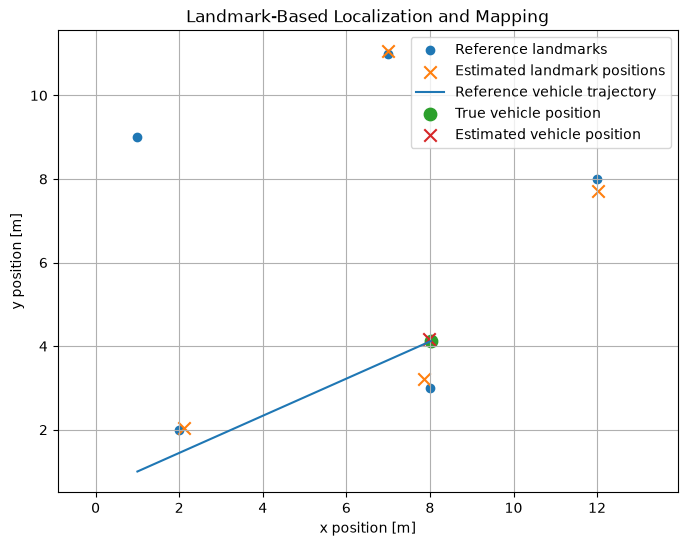

In [20]:
# 7-13D — Visualize Map, Vehicle Trajectory, and Landmark Observations

plt.figure(figsize=(8, 6))

# Reference landmark map
plt.scatter(
    landmarks[:, 0],
    landmarks[:, 1],
    label="Reference landmarks"
)

# Estimated landmark positions
plt.scatter(
    estimated_map_points[:, 0],
    estimated_map_points[:, 1],
    marker="x",
    s=80,
    label="Estimated landmark positions"
)

# Reference vehicle trajectory
plt.plot(
    true_poses[:, 0],
    true_poses[:, 1],
    label="Reference vehicle trajectory"
)

# True final vehicle position
plt.scatter(
    true_poses[-1, 0],
    true_poses[-1, 1],
    s=80,
    label="True vehicle position"
)

# Estimated final vehicle position
plt.scatter(
    estimated_pose[0],
    estimated_pose[1],
    marker="x",
    s=80,
    label="Estimated vehicle position"
)

plt.xlabel("x position [m]")
plt.ylabel("y position [m]")
plt.title("Landmark-Based Localization and Mapping")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

## Pose Estimation Error

The estimated vehicle pose can be compared with the reference pose.

For this experiment, the position error is evaluated using the
Euclidean distance between the estimated and reference positions.

In [21]:
# 8-13D — Calculate Vehicle Position Estimation Error

true_position = true_poses[-1, :2]
estimated_position = estimated_pose[:2]

position_error = np.linalg.norm(
    estimated_position - true_position
)

heading_error = np.abs(
    estimated_pose[2] - true_poses[-1, 2]
)

print(f"Position error: {position_error:.6f} m")
print(f"Heading error: {np.rad2deg(heading_error):.6f} deg")

Position error: 0.070564 m
Heading error: 0.000000 deg


## SLAM Limitations

The experiment demonstrates the relationship between landmark
observations, vehicle pose estimation, and map representation.

However, it is not a complete SLAM implementation.

The simplified experiment assumes:

- A known landmark map
- Known landmark correspondence
- Known vehicle heading
- Ideal landmark observations
- No sensor measurement noise
- No data-association uncertainty
- No loop-closure detection
- No optimization or graph-based back-end

A practical SLAM system must estimate the vehicle trajectory and map
from uncertain sensor observations while handling data association,
measurement noise, motion uncertainty, and accumulated estimation error.

Common SLAM approaches use probabilistic filtering or graph-based
optimization to address these challenges.

## Conclusion

The experiment introduced the fundamental relationship between
localization and mapping in SLAM.

Landmarks were represented in a world coordinate frame and observed
from the vehicle coordinate frame. The observations were transformed
back into the world frame and used to estimate the vehicle position
and represent the observed landmarks in the map.

The experiment demonstrated the relationship between localization and mapping that forms the basis of SLAM.

The vehicle pose determines how observations are placed in the map,
while observations of landmarks provide information about the vehicle
pose.

The implementation is intentionally simplified and should be viewed
as a conceptual SLAM foundation rather than a complete SLAM algorithm.